In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("online_retail_II.csv", encoding="ISO-8859-1")   # use your file name
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [2]:
print("Columns:", list(df.columns))
print("Shape:", df.shape)
print()
df.info()
print()
print("Nulls per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Shape: (1067371, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB

Nulls per column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Duplicate rows: 34335


In [3]:
df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


## Data Quality Overview

The dataset has 1,067,371 transactions from a UK online gift retailer between December 2009 and December 2011. Problems found: about 243,000 rows (22.8%) have no Customer ID, 34,335 rows are duplicates, and there are many returns and adjustments (negative quantities, cancelled invoices starting with "C", and prices of 0 or below).

In [4]:
print("Start:", df.shape)

df = df.dropna(subset=["Customer ID"])
print("After dropping missing Customer ID:", df.shape)

df = df.drop_duplicates()
print("After removing duplicates:", df.shape)

df["Invoice"] = df["Invoice"].astype(str)
df = df[~df["Invoice"].str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
print("After removing returns and bad prices:", df.shape)

df["Customer ID"] = df["Customer ID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["TotalPrice"] = df["Quantity"] * df["Price"]

print("Customers:", df["Customer ID"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
df[["Quantity", "Price", "TotalPrice"]].describe()

Start: (1067371, 8)
After dropping missing Customer ID: (824364, 8)
After removing duplicates: (797885, 8)
After removing returns and bad prices: (779425, 8)
Customers: 5878
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


,Quantity,Price,TotalPrice
count,779425.000000,779425.000000,779425.000000
mean,13.489370,3.218488,22.291823
std,145.855814,29.676140,227.427075
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.950000
50%,6.000000,1.950000,12.480000
75%,12.000000,3.750000,19.800000
max,80995.000000,10953.500000,168469.600000


## Data Quality Overview

The dataset has 1,067,371 transactions from a UK online gift retailer between December 2009 and December 2011. Problems found: about 243,000 rows (22.8%) have no Customer ID, 34,335 rows are duplicates, and there are many returns and adjustments (negative quantities, cancelled invoices starting with "C", and prices of 0 or below).

In [5]:
orders = df.groupby(["Customer ID", "Invoice"])["TotalPrice"].sum().reset_index()
per_customer = orders.groupby("Customer ID").agg(
    purchases=("Invoice", "nunique"),
    total_spent=("TotalPrice", "sum"),
    avg_order_value=("TotalPrice", "mean"),
)
print("Average order value:", round(orders["TotalPrice"].mean(), 2))
print("Average purchases per customer:", round(per_customer["purchases"].mean(), 2))
print("Average spend per customer (simple lifetime value):", round(per_customer["total_spent"].mean(), 2))
per_customer.describe().round(2)

Average order value: 469.98
Average purchases per customer: 6.29
Average spend per customer (simple lifetime value): 2955.9


,purchases,total_spent,avg_order_value
count,5878.00,5878.00,5878.00
mean,6.29,2955.90,385.18
std,13.01,14440.85,1214.29
min,1.00,2.95,2.95
25%,1.00,342.28,176.68
50%,3.00,867.74,279.24
75%,7.00,2248.31,414.90
max,398.00,580987.04,84236.25


## Descriptive Statistics

The average order is worth about 470, a customer places about 6.3 orders on average, and the average total spend per customer (a simple measure of customer lifetime value) is about 2,956. The median spend (868) is much lower than the mean, so a small number of high-value customers raise the average a lot.

In [6]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalPrice", "sum"),
)
print(rfm.shape)
rfm.describe().round(2)

(5878, 3)


,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,201.33,6.29,2955.90
std,209.34,13.01,14440.85
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,2248.30
max,739.00,398.00,580987.04


## RFM Features

I chose three behavioural features for each customer:
- **Recency:** days since the last purchase, measured from the day after the last date in the data (lower is better)
- **Frequency:** number of distinct invoices
- **Monetary:** total money spent

The median customer last bought 96 days before the end of the data, placed 3 orders and spent about 868. A quarter of customers bought only once. Frequency and Monetary are extremely right-skewed, since a few wholesale customers order hundreds of times and spend hundreds of thousands, so they need a transformation before clustering. Recency has two groups: recent buyers and a second group who last bought about a year ago.

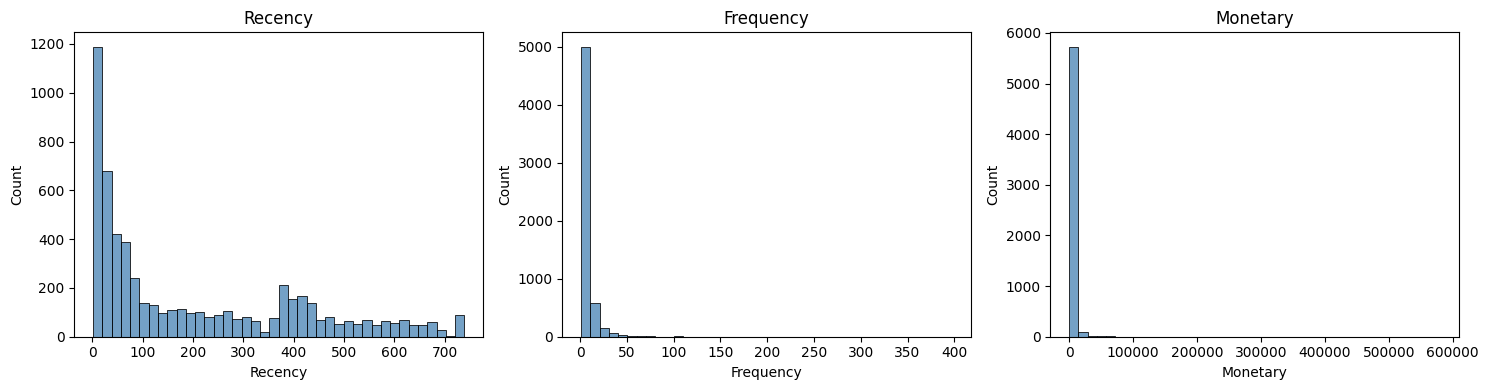

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a, c in zip(ax, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[c], bins=40, ax=a, color="steelblue")
    a.set_title(c)
plt.tight_layout()
plt.show()

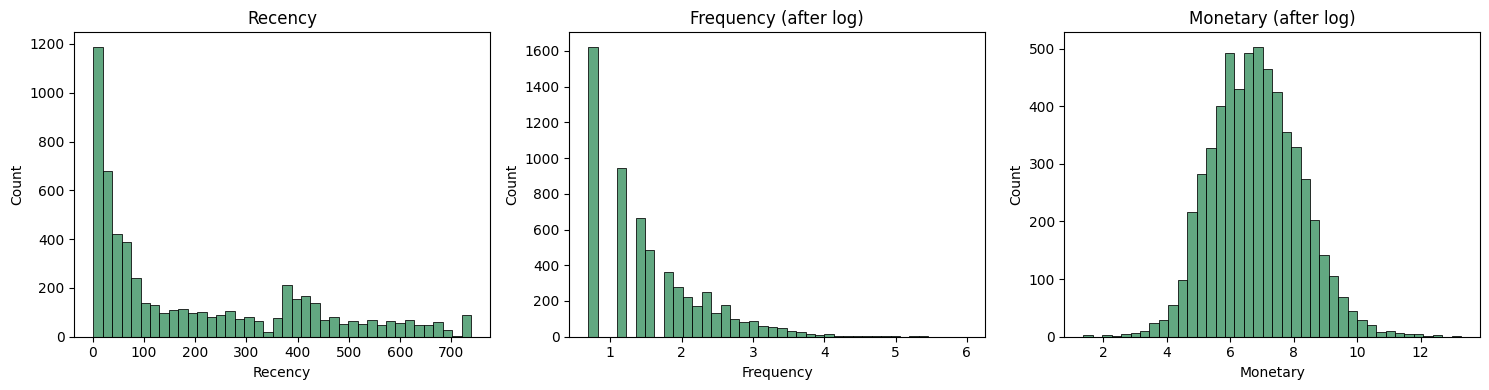

      Recency  Frequency  Monetary
mean     -0.0        0.0       0.0
std       1.0        1.0       1.0


In [8]:
from sklearn.preprocessing import StandardScaler

rfm_log = rfm.copy()
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a, c in zip(ax, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm_log[c], bins=40, ax=a, color="seagreen")
    a.set_title(c + " (after log)" if c != "Recency" else c)
plt.tight_layout()
plt.show()

print(pd.DataFrame(rfm_scaled, columns=rfm.columns).describe().round(2).loc[["mean", "std"]])

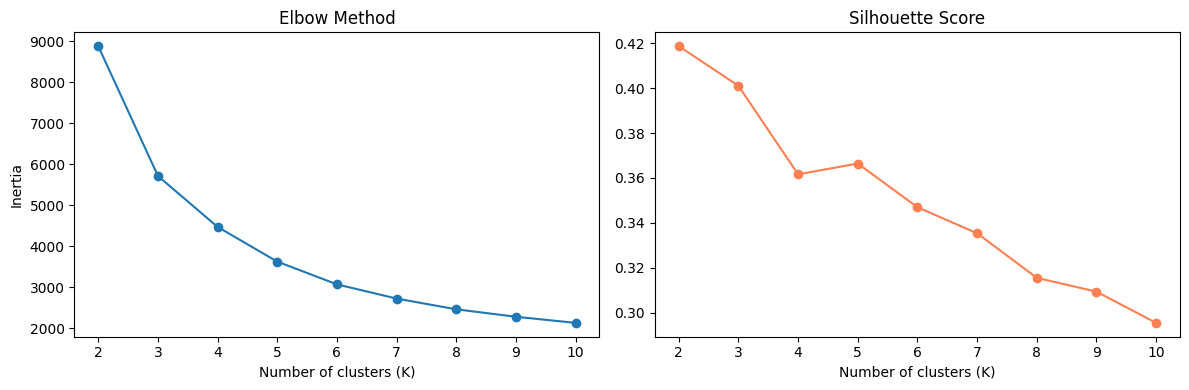

    K  Inertia  Silhouette
0   2   8881.0       0.419
1   3   5716.0       0.401
2   4   4473.0       0.362
3   5   3628.0       0.366
4   6   3072.0       0.347
5   7   2726.0       0.335
6   8   2464.0       0.316
7   9   2283.0       0.309
8  10   2133.0       0.295


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias, sils = [], []
ks = range(2, 11)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(rfm_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(rfm_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(list(ks), inertias, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Number of clusters (K)")
ax[0].set_ylabel("Inertia")
ax[1].plot(list(ks), sils, marker="o", color="coral")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Number of clusters (K)")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"K": list(ks), "Inertia": np.round(inertias), "Silhouette": np.round(sils, 3)}))

## Choosing the Number of Clusters

Frequency and Monetary were log-transformed because they were extremely right-skewed, and then all three features were standardised with StandardScaler so that no feature dominates the distance calculation. Monetary became nearly bell-shaped. Frequency is still skewed because it only takes whole numbers.

I ran K-Means for K = 2 to 10. The elbow plot bends around K = 3 to 4, where inertia stops dropping steeply. The silhouette score is highest at K = 2 (0.419) and K = 3 (0.401), but K = 2 only separates active from inactive customers, which is too coarse for targeted marketing. I chose K = 4 (silhouette 0.362), which is at the end of the elbow and gives groups that are more useful to act on.

In [10]:
km = KMeans(n_clusters=4, n_init=10, random_state=42)
rfm["Cluster"] = km.fit_predict(rfm_scaled)

profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
).round(1)
profile["% of customers"] = (profile["Customers"] / profile["Customers"].sum() * 100).round(1)
profile["% of revenue"] = (rfm.groupby("Cluster")["Monetary"].sum() / rfm["Monetary"].sum() * 100).round(1)
profile

,Customers,Recency,Frequency,Monetary,% of customers,% of revenue
Cluster,,,,,,
0,1494,102.9,1.8,460.7,25.4,4.0
1,1646,492.1,1.7,521.3,28.0,4.9
2,876,38.4,23.4,13656.7,14.9,68.9
3,1862,99.9,5.9,2075.8,31.7,22.2


## Cluster Profiles

K-Means with K = 4 produced four customer segments. The table shows each segment's average Recency, Frequency and Monetary values, plus its share of customers and revenue.

| Segment | Customers | Avg Recency (days) | Avg Frequency | Avg Monetary | % customers | % revenue |
|---|---|---|---|---|---|---|
| Champions | 876 | 38 | 23.4 | 13,657 | 14.9% | 68.9% |
| Loyal Regulars | 1,862 | 100 | 5.9 | 2,076 | 31.7% | 22.2% |
| Recent Low-Spenders | 1,494 | 103 | 1.8 | 461 | 25.4% | 4.0% |
| Lapsed / Lost | 1,646 | 492 | 1.7 | 521 | 28.0% | 4.9% |

- **Champions** buy very often, spend the most and bought recently. They are only 15% of customers but bring in almost 69% of revenue.
- **Loyal Regulars** are the largest group. They buy several times, spend a moderate amount and are still active.
- **Recent Low-Spenders** bought recently but have placed only about two orders and spend little. They may be new or occasional customers.
- **Lapsed / Lost** also placed about two orders, but their last purchase was over a year ago.

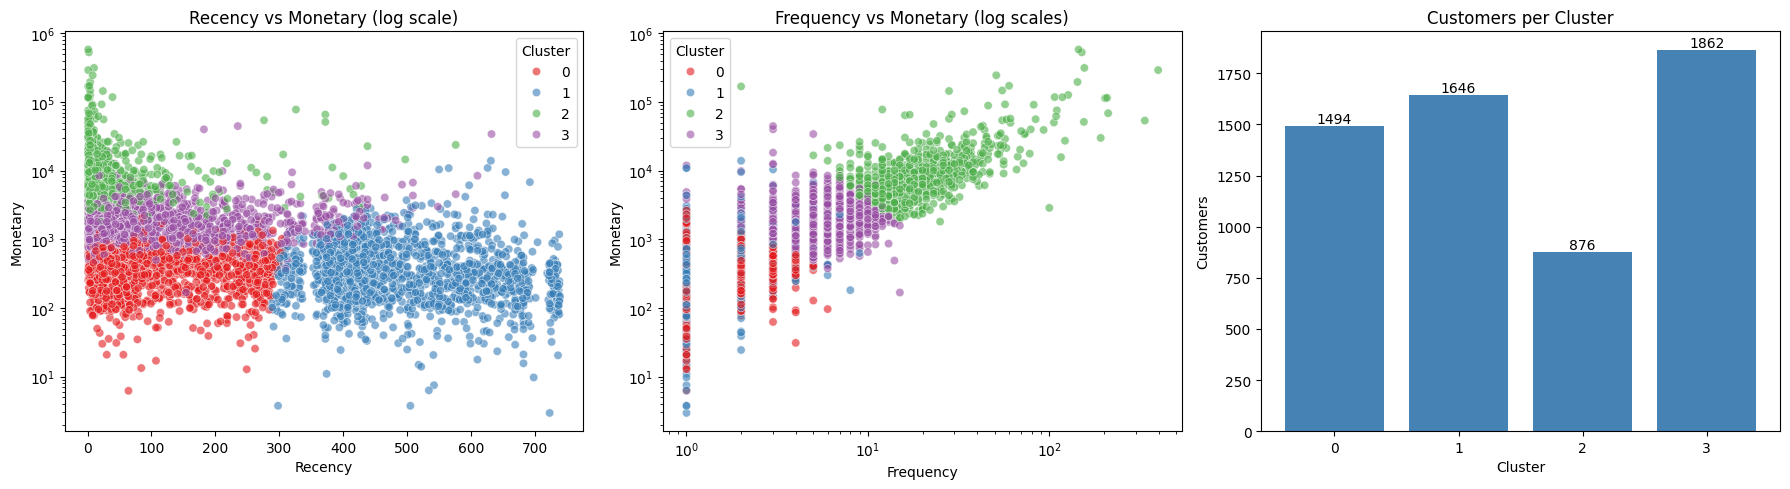

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18,5))

sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Cluster", palette="Set1", alpha=0.6, ax=ax[0])
ax[0].set_yscale("log")
ax[0].set_title("Recency vs Monetary (log scale)")

sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Cluster", palette="Set1", alpha=0.6, ax=ax[1])
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_title("Frequency vs Monetary (log scales)")

sizes = rfm["Cluster"].value_counts().sort_index()
ax[2].bar(sizes.index.astype(str), sizes.values, color="steelblue")
ax[2].set_title("Customers per Cluster")
ax[2].set_xlabel("Cluster")
ax[2].set_ylabel("Customers")
for i, v in enumerate(sizes.values):
    ax[2].text(i, v, str(v), ha="center", va="bottom")

plt.tight_layout()
plt.show()

## Cluster Visualisation

The scatter plots show the clusters on Recency vs Monetary and Frequency vs Monetary (log scales are used on the axes only, to make the points readable). Champions sit at the top right, with high frequency and high spend. Lapsed customers are the only group with Recency above about 300 days. Recent Low-Spenders and Lapsed customers overlap a lot on Frequency and Monetary, and what separates them is how long ago they last purchased. The bar chart shows the number of customers per segment: Loyal Regulars are the largest (1,862) and Champions the smallest (876).

## Insights and Marketing Recommendations

- **Champions (15% of customers, 69% of revenue):** Protect these customers first. Offer early access to new products, a loyalty or VIP programme, and personal account service. Losing a few of them would hurt revenue more than losing hundreds of low-spenders.
- **Loyal Regulars (32%, 22% of revenue):** These are the best group to grow. Use cross-selling, bundle offers and volume discounts to encourage larger and more frequent orders so that some of them become Champions.
- **Recent Low-Spenders (25%, 4% of revenue):** Treat them as new customers. Send a welcome series and a second-purchase offer to turn a one-off order into a habit, before they drift away.
- **Lapsed / Lost (28%, 5% of revenue):** Run a low-cost win-back campaign, such as a "we miss you" email with a discount. Because they bring little revenue, spend only a limited budget on them and stop contacting those who don't respond.

**Limitations:** The segments are based only on three features (Recency, Frequency and Monetary). Frequency and Monetary were log-transformed, and the very large wholesale customers form much of the Champions group. The cluster count (K = 4) was a judgement call between K = 3 and K = 4, and these segments should be re-checked on new data.